# 24 · Scam-push detection (work package 13)

**Work package 13** of the [applications plan](../../research/implementation_plan_applications.md), section 13.
When a token suddenly gets many new buyers, is the buying something the recommender could explain (accounts like
its usual traders, through co-trading paths), or not? Unexplained demand could be a push, and pushes collapse.

- **Windows:** the 24 hours after each evaluation point and the 24 hours after that (70 decision days); tokens that
  existed before the point and got at least 20 new accounts in the window.
- **Recommender features:** share of new accounts with no co-trading path to the token (outside the popular
  head), share for which it ranked in their worst 10% among active tokens, burst (last hour / whole window), share
  of new accounts in WP10 farm groups.
- **Baseline features:** token age, accounts so far, accounts in the last hour, buy share.
- **Label (prices only):** within 72 hours after the window, the price falls more than 90% below its peak and
  trading stops (fewer than 5 swaps in the last 24 hours); a token with no real swap at all is dead (collapsed).
- **Criterion (stated in the plan):** a logistic regression with the four recommender features added to the
  baseline raises the AUC for collapse on Dev B, and on the test, with a 95% bootstrap interval over days of the
  AUC difference that excludes zero. Both models are fitted on Dev A.

Built by `src/scripts/build_scam_push.py` (results/wp13/). Choices in `project_direction.md` (24 November).

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

import plots
import protocol as pc
import scam_push as sp

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
windows = pd.read_parquet(pc.RESULTS_DIR / "wp13" / "tokens.parquet")
windows["day"] = windows["window_start"].dt.floor("D")
windows.groupby("part").agg(days=("day", "nunique"), token_windows=("token", "size"), tokens=("token", "nunique"),
                            collapsed=("collapsed", "mean"), median_new_accounts=("new_accounts", "median"),
                            ranked_share=("ranked_accounts", lambda r: (r / windows.loc[r.index, "new_accounts"]).median())).loc[list(pc.POINTS)]  # fmt: skip

,days,token_windows,tokens,collapsed,median_new_accounts,ranked_share
part,,,,,,
dev_a,20,2393,529,0.017,34.000,0.417
dev_b,22,2284,578,0.020,35.000,0.400
test,28,4204,769,0.013,35.000,0.432


`ranked_share`: the median share of a token's new accounts that the recommender ranked (evaluated accounts with a
history); the recommender features are computed over these.

## 1. The features, collapsed against not collapsed (Dev A)

In [2]:
dev_a = windows[windows["part"] == "dev_a"]
features = sp.RECOMMENDER_FEATURES + ["age_days", "accounts_before", "accounts_last_hour", "buy_share"]
dev_a.groupby("collapsed")[features].median().T

collapsed,False,True
unexplained_share,0.000,0.087
low_rank_share,0.000,0.000
burst,0.024,0.000
farm_share,0.029,0.006
age_days,22.000,14.092
accounts_before,829.000,421.000
accounts_last_hour,4.000,1.000
buy_share,0.502,0.544


In [3]:
pd.Series({f: roc_auc_score(dev_a["collapsed"], dev_a[f].fillna(dev_a[f].median())) for f in features}, name="AUC alone on Dev A (0.5 = no signal; below 0.5 = lower values collapse)")

unexplained_share    0.653
low_rank_share       0.512
burst                0.446
farm_share           0.477
age_days             0.302
accounts_before      0.363
accounts_last_hour   0.471
buy_share            0.620
Name: AUC alone on Dev A (0.5 = no signal; below 0.5 = lower values collapse), dtype: float64

## 2. The criterion: Dev B and test

Both models fitted on Dev A; AUC on each part, the difference with a bootstrap over days, and the share of
collapsed tokens among the 1% (and 5%) highest scores.

In [4]:
COMBINED = sp.BASELINE_FEATURES + sp.RECOMMENDER_FEATURES
rows, scored = [], {}
for part in ("dev_b", "test"):
    test = windows[windows["part"] == part]
    base = sp.fit_score(dev_a, test, sp.BASELINE_FEATURES)
    combined = sp.fit_score(dev_a, test, COMBINED)
    alone = sp.fit_score(dev_a, test, sp.RECOMMENDER_FEATURES)
    result = sp.auc_difference_by_day(base, combined, test["collapsed"].to_numpy(), test["day"].to_numpy())
    result.update({"part": part, "auc_recommender_alone": roc_auc_score(test["collapsed"], alone),
                   "precision_top1_base": sp.precision_at(base, test["collapsed"]), "precision_top1_combined": sp.precision_at(combined, test["collapsed"]),
                   "precision_top5_base": sp.precision_at(base, test["collapsed"], 0.05), "precision_top5_combined": sp.precision_at(combined, test["collapsed"], 0.05),
                   "collapse_rate": test["collapsed"].mean()})  # fmt: skip
    rows.append(result)
    scored[part] = (test, base, combined)
criterion = pd.DataFrame(rows).set_index("part")
criterion.T

part,dev_b,test
auc_a,0.939,0.933
auc_b,0.921,0.926
difference,-0.019,-0.007
low,-0.032,-0.018
high,-0.006,0.005
days,22.000,28.000
tokens,"2,284.000","4,204.000"
collapsed,45.000,55.000
auc_recommender_alone,0.687,0.738
precision_top1_base,0.478,0.214


In [5]:
for part, row in criterion.iterrows():
    met = row["difference"] > 0 and row["low"] > 0
    print(f"{part}: AUC {row['auc_a']:.3f} -> {row['auc_b']:.3f}, difference {row['difference']:+.3f} [{row['low']:+.3f}, {row['high']:+.3f}] -> {'excludes zero' if met else 'does not exclude zero'}")
MET = bool(((criterion["difference"] > 0) & (criterion["low"] > 0)).all())
print(f"Criterion (Dev B and test): {'MET' if MET else 'NOT met'}")

dev_b: AUC 0.939 -> 0.921, difference -0.019 [-0.032, -0.006] -> does not exclude zero
test: AUC 0.933 -> 0.926, difference -0.007 [-0.018, +0.005] -> does not exclude zero
Criterion (Dev B and test): NOT met


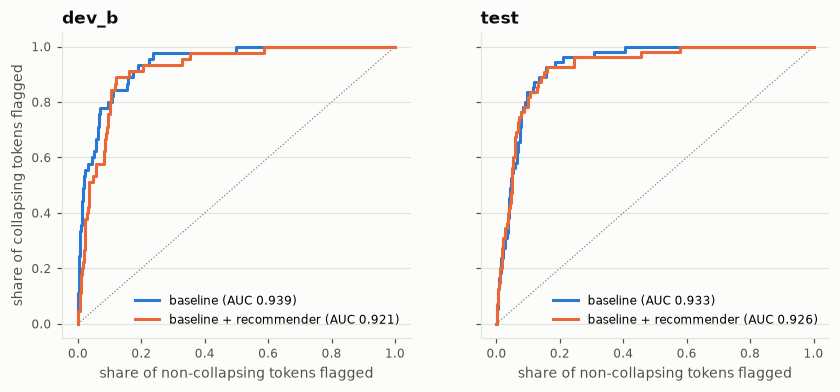

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, (part, (test, base, combined)) in zip(axes, scored.items()):
    for slot, (label, score) in enumerate([("baseline", base), ("baseline + recommender", combined)]):
        fpr, tpr, _ = roc_curve(test["collapsed"], score)
        ax.plot(fpr, tpr, color=plots.SERIES[slot], label=f"{label} (AUC {roc_auc_score(test['collapsed'], score):.3f})")
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", linewidth=0.8)
    ax.set_title(part)
    ax.set_xlabel("share of non-collapsing tokens flagged")
    ax.legend(fontsize=8)
axes[0].set_ylabel("share of collapsing tokens flagged")
plt.show()

## 3. The fitted model (Dev A)

Coefficients of the combined model on standardized features: positive means more likely to collapse.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(dev_a[COMBINED].fillna(dev_a[COMBINED].median()), dev_a["collapsed"])
pd.Series(model[-1].coef_[0], index=COMBINED, name="coefficient").sort_values()

log_accounts_before      -0.598
log_age_days             -0.464
farm_share               -0.222
buy_share                -0.146
burst                    -0.136
low_rank_share            0.074
unexplained_share         0.323
log_accounts_last_hour    0.558
Name: coefficient, dtype: float64

## 4. By token age

The AUC of both models on the test within age bands at the decision (does the recommender help where age alone
does not?).

In [8]:
test, base, combined = scored["test"]
test = test.assign(base=base, combined=combined, band=pd.cut(test["age_days"], [0, 1, 7, np.inf], labels=["< 1 day", "1-7 days", "> 7 days"]))
rows = []
for band, part in test.groupby("band", observed=True):
    if part["collapsed"].nunique() == 2:
        rows.append({"age": band, "tokens": len(part), "collapse_rate": part["collapsed"].mean(),
                     "auc_base": roc_auc_score(part["collapsed"], part["base"]), "auc_combined": roc_auc_score(part["collapsed"], part["combined"])})  # fmt: skip
pd.DataFrame(rows)

,age,tokens,collapse_rate,auc_base,auc_combined
0,1-7 days,136,0.125,0.626,0.325
1,> 7 days,4068,0.009,0.934,0.927


## 5. Copycats (deferred from WP12)

A token is a **copycat** here when its readable symbol (case ignored) equals that of a token launched earlier in
the data. Collapse rates of copycats and other tokens, by age band, over all scored windows.

In [9]:
import token_data as td

tokens = td.load_tokens()
meta = pd.read_parquet(td.PROJECT_DIR / "token_metadata.parquet").drop_duplicates("address").set_index("address")["symbol"]
tokens["symbol_key"] = tokens["address"].map(meta).astype("string").str.strip().str.lower()
tokens = tokens.sort_values("first_timestamp")
tokens["copycat"] = tokens["symbol_key"].notna() & (tokens["symbol_key"] != "") & tokens.duplicated("symbol_key", keep="first")
all_windows = windows.assign(copycat=windows["token"].map(tokens.set_index("token_id")["copycat"]).fillna(False).astype(bool),
                             band=pd.cut(windows["age_days"], [0, 1, 7, np.inf], labels=["< 1 day", "1-7 days", "> 7 days"]))  # fmt: skip
all_windows.groupby(["band", "copycat"], observed=True)["collapsed"].agg(["size", "mean"]).unstack("copycat")

size        mean      
copycat  False True  False True 
band                            
1-7 days   119   213 0.076 0.192
> 7 days  7872   677 0.008 0.043

## 6. What this shows

- **The label was corrected once** (`project_direction.md`, 24 November): the first run counted only swaps against
  WETH, USDC and USDT, so tokens still trading in other pools looked dead (7.3% "collapsed", 97% of them for that
  reason). Counting trades in every pool, 1.6% of token windows collapse: 45 on Dev B and 55 on test.
- **The criterion is not met.** The baseline, from what anyone can see, already ranks collapsing tokens very well
  (AUC 0.939 on Dev B, 0.933 on test): tokens that collapse are smaller (median 421 accounts so far against 829)
  and younger. Adding the recommender's four features lowers the AUC slightly: −0.019 (interval −0.032 to −0.006)
  on Dev B and −0.007 (−0.018 to +0.005) on test. Precision among the top 1% also falls.
- **The unexplained share carries a signal, but not a new one.** On its own, the share of new accounts with no
  co-trading path is higher for collapsing tokens (median 0.09 against 0) and reaches an AUC of 0.65 on Dev A; the
  four recommender features alone reach 0.69 on Dev B and 0.74 on test. But what they know is already in the size
  and age of the token. The low-rank share and the burst carry nothing (AUC about 0.5).
- **The setting misses the real pushes.** Only tokens that existed at the evaluation point can be ranked, and with
  at least 20 new accounts in a day almost all scored tokens are older than a week (median 22 days); no scored
  token was younger than a day. Fresh launches, where pushes and rug pulls happen, are cold for the model. This
  is the cold-start limit of the project again.
- **Copycats collapse more.** Tokens reusing an older token's symbol collapse 19% of the time at 1-7 days old
  (others: 8%) and 4.3% when older (others: 0.8%), about five times as often. A symbol match is a cheaper warning
  than anything the recommender adds here.

(Written after the run.)